# `pp.banksy_matrix` vs `banksy_py`

Astrolabe's BANKSY feature augmentation (Singhal et al. 2024, *Nature Genetics*) is a from-scratch reimplementation rather than a wrapper around the official `banksy_py` package (installed here as `banksy-py` on PyPI, a maintained fork of `prabhakarlab/Banksy_py`), keeping astrolabe free of its extra dependencies. This notebook builds the raw, un-lambda-weighted M0 (neighbor mean) and |M1| (azimuthal Gabor filter magnitude) blocks with each implementation and compares them directly.

One deliberate difference remains: banksy_py builds a larger neighbor set for the AGF (|M1|, m=1) term than for M0 (twice as many, since a directional profile benefits from more points than a plain mean), while astrolabe reuses one k-neighbor graph for both. M0 and |M1| are reported separately below so this gap, if any, stays visible.


In [1]:
import logging
logging.basicConfig(level=logging.INFO)

import time
import numpy as np
import astrolabe as ab

from banksy.initialize_banksy import initialize_banksy
from banksy.embed_banksy import generate_banksy_matrix


INFO:astrolabe.pl._theme:Registered bundled Inter font files with matplotlib


INFO:astrolabe.pl._theme:astrolabe plot theme set to 'light'


## Dataset

`ab.datasets.xenium_tiny()`, QC'd, normalized, log1p'd - the same preprocessed expression matrix is handed to both implementations so any disagreement reflects the neighborhood-feature computation itself, not a difference in input data.


In [2]:
mdata = ab.datasets.xenium_tiny()
ab.pipeline.filter_xenium(mdata)
ab.pp.normalize_total(mdata)
ab.pp.log1p(mdata)

adata = mdata["xenium"]
n_genes = adata.n_vars
n_neighbors = 6
adata


INFO:astrolabe.io._xenium:Reading Xenium run 'outs' from C:\Users\Austin\PycharmProjects\astrolabe\benchmarks\banksy_py\.astrolabe_cache\datasets\xenium_tiny\outs


C:\Users\Austin\PycharmProjects\astrolabe\astrolabe\io\_xenium.py:870: ExperimentalFeatureWarning: Support for Awkward Arrays is currently experimental. Behavior may change in the future. Please report any issues you may encounter!
  adata.obsm[obsm_key] = ak.Array(
INFO:astrolabe.io._xenium:Loaded 358 cells × 520 features (115 control probes)


INFO:astrolabe.io._xenium:Streaming transcripts from C:\Users\Austin\PycharmProjects\astrolabe\benchmarks\banksy_py\.astrolabe_cache\datasets\xenium_tiny\outs\transcripts.parquet


INFO:astrolabe.io._xenium:Loaded 20999 transcript detections


INFO:astrolabe.pipeline:filter_xenium: 358 cells × 520 genes


...

INFO:astrolabe.pp._qc:filter_genes: removing 115 / 370 features


INFO:astrolabe.pp._qc:  synced uns['transcripts']: 20163 -> 20160 rows (dropped filtered-out genes)


INFO:astrolabe.pipeline:  [remove_controls] 370 → 255 genes  (removed 115, 31.1%)


INFO:astrolabe.pipeline:filter_xenium: done — 328 cells × 255 genes


AnnData object with n_obs × n_vars = 328 × 255
    obs: 'cell_area', 'nucleus_area', 'transcript_counts', 'control_probe_counts', 'control_codeword_counts', 'nucleus_count', 'unassigned_codeword_total', 'deprecated_codeword_total', 'genomic_control_probe_total', 'negative_control_codeword_total', 'negative_control_probe_total', 'any_negative_control_probe_total', 'n_unassigned_codewords', 'n_deprecated_codewords', 'n_genomic_control_probes', 'n_negative_control_codewords', 'n_negative_control_probes', 'n_any_negative_control_probes', 'pct_unassigned_codewords', 'pct_deprecated_codewords', 'pct_genomic_control_probes', 'pct_negative_control_codewords', 'pct_negative_control_probes', 'pct_any_negative_control_probes', 'pct_counts_control', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'nucleus_to_cell_area_ratio', 'has_nucleus', 'total_counts_norm'
    var: 

## Astrolabe: `pp.banksy_matrix`

`agf=True` requests both the M0 and |M1| blocks. `obsm['X_banksy']` is `[sqrt(1-lambda)*X, sqrt(lambda*(1-kappa))*M0, sqrt(lambda*kappa)*|M1|]` - dividing out the known scalar weights recovers the raw, un-weighted M0/|M1| blocks for comparison.


In [3]:
_t0 = time.perf_counter()
ab.tl.spatial_neighbors(mdata, n_neighbors=n_neighbors)

lam, kappa = 0.2, 0.5
ab.pp.banksy_matrix(mdata, lambda_param=lam, agf=True, agf_weight=kappa)
t_astro_s = time.perf_counter() - _t0
print(f"astrolabe runtime (graph + banksy_matrix): {t_astro_s:.4f}s")

X_banksy = adata.obsm["X_banksy"]
m0_astro = X_banksy[:, n_genes:2 * n_genes] / np.sqrt(lam * (1 - kappa))
m1_astro = X_banksy[:, 2 * n_genes:3 * n_genes] / np.sqrt(lam * kappa)
m0_astro.shape, m1_astro.shape


INFO:astrolabe.tl._graph:spatial_neighbors: 328 cells, 2266 edges (mean degree 6.9) [generic]


INFO:astrolabe.pp._banksy:banksy_matrix: λ=0.20  agf=True  → obsm['X_banksy']  shape=(328, 765)


astrolabe runtime (graph + banksy_matrix): 0.0119s


((328, 255), (328, 255))

## Reference: `banksy_py`

Runs on a fresh copy so astrolabe's own spatial graph/state never leaks into `banksy_py`'s KNN construction - each tool builds its neighbor graph from scratch on the same `obsm['spatial']` coordinates. `generate_banksy_matrix`'s pre-lambda-weighting concatenation (`banksy_dict[nbr_weight_decay]['norm_counts_concatenated']`) is `[X, M0, M1]`, the raw blocks before any `sqrt(lambda...)` scaling, so it's used directly with no further arithmetic needed to undo.


In [4]:
adata_ref = adata.copy()
adata_ref.obsm["spatial"] = np.asarray(adata_ref.obsm["spatial"], dtype=np.float64)

_t0 = time.perf_counter()
banksy_dict = initialize_banksy(
    adata_ref, coord_keys=("x", "y", "spatial"),
    num_neighbours=n_neighbors, nbr_weight_decay="scaled_gaussian", max_m=1,
    plt_edge_hist=False, plt_nbr_weights=False, plt_agf_angles=False, plt_theta=False,
)
banksy_dict, _ = generate_banksy_matrix(
    adata_ref, banksy_dict, lambda_list=[lam], max_m=1,
    plot_std=False, save_matrix=False, verbose=False,
)
t_ref_s = time.perf_counter() - _t0
print(f"reference runtime (graph + banksy matrix): {t_ref_s:.4f}s")

concatenated = banksy_dict["scaled_gaussian"]["norm_counts_concatenated"]
concatenated = np.asarray(concatenated.todense() if hasattr(concatenated, "todense") else concatenated)
m0_ref = concatenated[:, n_genes:2 * n_genes]
m1_ref = concatenated[:, 2 * n_genes:3 * n_genes]
m0_ref.shape, m1_ref.shape



Median distance to closest cell = 6.310249998015813

---- Ran median_dist_to_nearest_neighbour in 0.00 s ----

---- Ran generate_spatial_distance_graph in 0.00 s ----

---- Ran row_normalize in 0.00 s ----

---- Ran generate_spatial_weights_fixed_nbrs in 0.01 s ----

---- Ran generate_spatial_distance_graph in 0.00 s ----

---- Ran theta_from_spatial_graph in 0.00 s ----

---- Ran row_normalize in 0.00 s ----

---- Ran generate_spatial_weights_fixed_nbrs in 0.01 s ----

Check if X contains only finite (non-NAN) values
Decay Type: scaled_gaussian
Weights Object: {'weights': {0: <Compressed Sparse Row sparse matrix of dtype 'float64'
	with 1968 stored elements and shape (328, 328)>, 1: <Compressed Sparse Row sparse matrix of dtype 'complex128'
	with 3936 stored elements and shape (328, 328)>}}

Nbr matrix | Mean: 0.08 | Std: 0.2
Size of Nbr | Shape: (328, 255)
Top 3 entries of Nbr Mat:

[[0.         0.07697079 0.25074663]
 [0.         0.49627465 0.25717429]
 [0.         0.23373465 0.098

Ran 'Create BANKSY Matrix' in 0.0 mins


Scale factors squared: [0.8        0.13333333 0.06666667]
Scale factors: [0.89442719 0.36514837 0.25819889]
reference runtime (graph + banksy matrix): 0.3638s


((328, 255), (328, 255))

## Agreement


M0 (neighbor mean):        Pearson r = 0.9960, Spearman rho = 0.9681
|M1| (AGF magnitude):      Pearson r = 0.8329, Spearman rho = 0.8764
Runtime: astrolabe 0.0119s vs banksy_py 0.3638s (30.7x astrolabe faster)


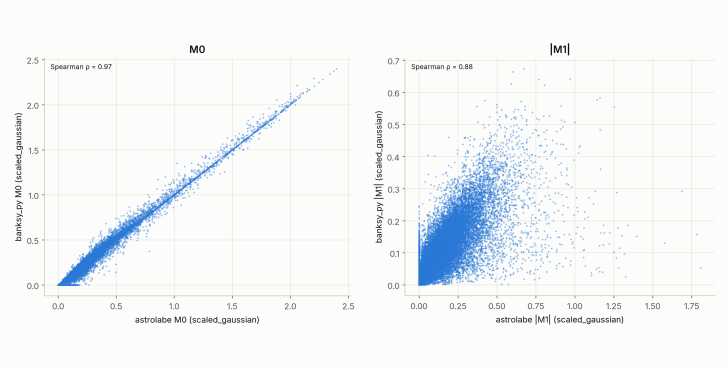

In [5]:
from scipy.stats import spearmanr

r_m0 = np.corrcoef(m0_astro.ravel(), m0_ref.ravel())[0, 1]
rho_m0 = spearmanr(m0_astro.ravel(), m0_ref.ravel()).statistic
r_m1 = np.corrcoef(m1_astro.ravel(), m1_ref.ravel())[0, 1]
rho_m1 = spearmanr(m1_astro.ravel(), m1_ref.ravel()).statistic

print(f"M0 (neighbor mean):        Pearson r = {r_m0:.4f}, Spearman rho = {rho_m0:.4f}")
print(f"|M1| (AGF magnitude):      Pearson r = {r_m1:.4f}, Spearman rho = {rho_m1:.4f}")
print(f"Runtime: astrolabe {t_astro_s:.4f}s vs banksy_py {t_ref_s:.4f}s "
      f"({max(t_astro_s, t_ref_s) / min(t_astro_s, t_ref_s):.1f}x astrolabe {'faster' if t_astro_s < t_ref_s else 'slower'})")

panel = (
    ab.pl.scatter(
        adata, x=m0_astro.ravel(), y=m0_ref.ravel(), annotate_corr=True,
        xlabel="astrolabe M0 (scaled_gaussian)", ylabel="banksy_py M0 (scaled_gaussian)", title="M0",
    )
    | ab.pl.scatter(
        adata, x=m1_astro.ravel(), y=m1_ref.ravel(), annotate_corr=True,
        xlabel="astrolabe |M1| (scaled_gaussian)", ylabel="banksy_py |M1| (scaled_gaussian)", title="|M1|",
    )
)
panel.show()


## Interpretation

Both blocks use the same `scaled_gaussian` weighting scheme, so M0 should correlate strongly since both implementations compute the same quantity from the same neighbor set. |M1| is the more informative number: astrolabe estimates the azimuthal profile from the same k-neighbor set used for M0, while banksy_py uses a larger neighbor set for this term (see note above), so a somewhat weaker |M1| correlation than M0's is the expected signature of that difference, not a bug.
